In [13]:
%matplotlib widget

import numpy as np
import matplotlib.pyplot as plt
import csv

In [10]:
# Load csv
def load_csv_results_data(file_name):
    points_lf = []
    points_hf = []
    model_error = []
    training_time = []
    evaluation_time = []
    with open(file_name,mode='r') as file:
        reader = csv.reader(file)
        for row in reader:
            print(row)
            points_lf.append(int(row[0]))
            points_hf.append(int(row[1]))
            model_error.append(float(row[2]))
            training_time.append(float(row[3]))
            evaluation_time.append(float(row[4]))
    return points_lf, points_hf, model_error, training_time, evaluation_time

In [ ]:
# Function plotting

def plot_cokriging_data(
    points_lf,
    points_hf,
    output,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot(projection="3d")
    ax.set_title(name)
    ax.set_xlabel("Samples LF")
    ax.set_ylabel("Samples HF")
    ax.set_zlabel(label)

    if log_output:
        output = np.log10(output)

    ax.scatter(
        points_lf,
        points_hf,
        output,
        color=color,
        label=label,
    )


def plot_cokriging_data_slice(
    points_lf,
    points_hf,
    output,
    fix_lf=True,
    fix_value=10,
    name="Cokriging Data",
    color="black",
    label="data",
    log_output=False,
    ax=None,
):
    if ax == None:
        plt.close()
        fig = plt.figure(name)
        ax = fig.add_subplot()
    ax.set_title(name)
    x_values = []
    y_values = []
    if fix_lf:
        ax.set_xlabel("Samples HF")
        for i, val in enumerate(points_lf):
            if val == fix_value:
                x_values.append(points_hf[i])
                y_values.append(output[i])
    else:
        ax.set_xlabel("Samples_LF")
        for i, val in enumerate(points_hf):
            if val == fix_value:
                x_values.append(points_lf[i])
                y_values.append(output[i])
    ax.set_ylabel(label)

    if log_output:
        y_values = np.log10(y_values)

    print(x_values)
    ax.scatter(
        x_values,
        y_values,
        color=color,
        label=label,
    )
    return ax

In [11]:
loaded_lf,loaded_hf,loaded_error,loaded_train_time,loaded_evaluation_time = load_csv_results_data('CokrigingResults.csv')

['0', '5', '4.069865623722557', '0.05182319995947182', '0.001232100068591535']
['0', '5', '4.467115020253341', '0.028579700039699674', '0.0013066999381408095']
['0', '5', '4.606708254795112', '0.04300689999945462', '0.0014974999940022826']
['2', '5', '6.568344297987771', '0.1724151000380516', '0.002571500022895634']
['2', '5', '4.054000940615591', '0.12214340001810342', '0.0021059999708086252']
['2', '5', '7.058009974295041', '0.30355490010697395', '0.0020769000984728336']
['4', '5', '3.87344198910084', '0.15129379997961223', '0.002248200005851686']
['4', '5', '5.0043436497120055', '0.17648339993320405', '0.0021933000534772873']
['4', '5', '5.6741918505536315', '0.14764239999931306', '0.0025252000195905566']
['6', '5', '1.417263141874709', '0.26889399997889996', '0.0035749999806284904']
['6', '5', '3.6428033794430847', '0.09885099995881319', '0.0029713999247178435']
['6', '5', '4.70225179481559', '0.18729809997603297', '0.0029045999981462955']
['8', '5', '5.332878658077969', '0.1616511

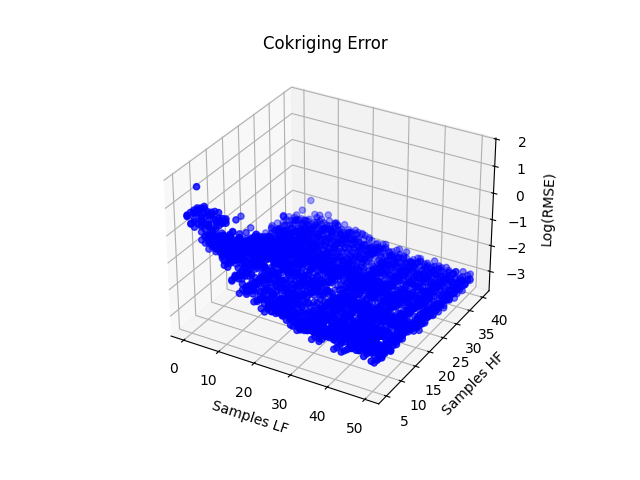

In [20]:
ax = plot_cokriging_data(
    points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, label="Log(RMSE)",name="Cokriging Error ",log_output=True, color="blue"
)
plt.show()

[5, 5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 9, 10, 10, 10, 11, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 16, 17, 17, 17, 18, 18, 18, 19, 19, 19, 20, 20, 20, 21, 21, 21, 22, 22, 22, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 26, 27, 27, 27, 28, 28, 28, 29, 29, 29, 30, 30, 30, 31, 31, 31, 32, 32, 32, 33, 33, 33, 34, 34, 34, 35, 35, 35, 36, 36, 36, 37, 37, 37, 38, 38, 38, 39, 39, 39, 40, 40, 40]


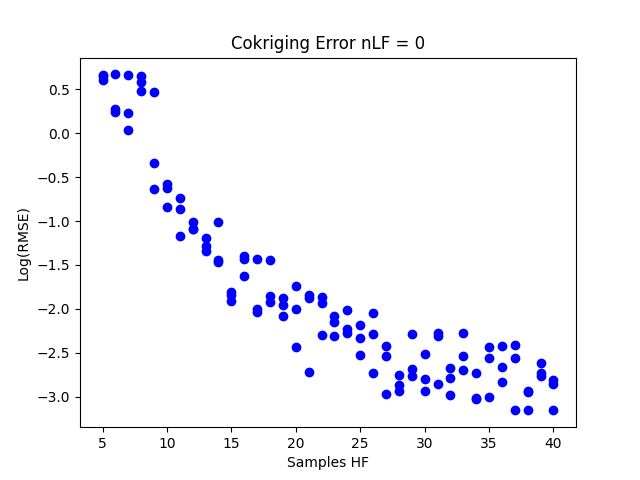

In [18]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=0, label="Log(RMSE)",name="Cokriging Error nLF = 0",log_output=True, color="blue")
plt.show(ax)

[5, 5, 5, 6, 6, 6, 7, 7, 7, 8, 8, 8, 9, 9, 9, 10, 10, 10, 11, 11, 11, 12, 12, 12, 13, 13, 13, 14, 14, 14, 15, 15, 15, 16, 16, 16, 17, 17, 17, 18, 18, 18, 19, 19, 19, 20, 20, 20, 21, 21, 21, 22, 22, 22, 23, 23, 23, 24, 24, 24, 25, 25, 25, 26, 26, 26, 27, 27, 27, 28, 28, 28, 29, 29, 29, 30, 30, 30, 31, 31, 31, 32, 32, 32, 33, 33, 33, 34, 34, 34, 35, 35, 35, 36, 36, 36, 37, 37, 37, 38, 38, 38, 39, 39, 39, 40, 40, 40]


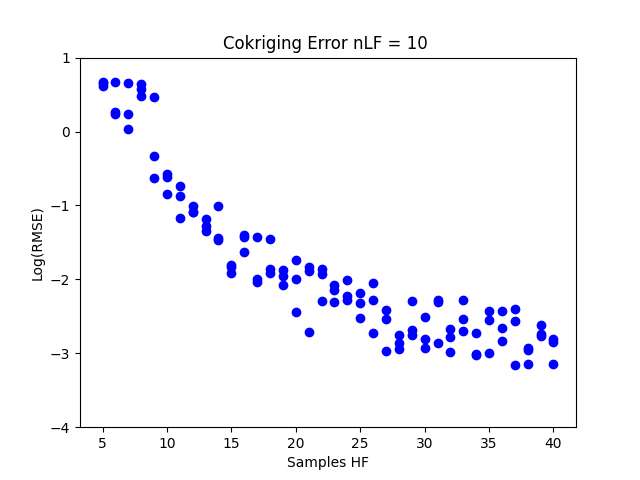

In [23]:
ax = plot_cokriging_data_slice(points_lf=loaded_lf, points_hf=loaded_hf, output=loaded_error, fix_lf=True,fix_value=0, label="Log(RMSE)",name="Cokriging Error nLF = 10 ",log_output=True, color="blue")
ax.set_ybound(-4.0,1.0)
plt.show(ax)